# Modeling: Churn Classification

In [41]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)

train = pd.read_csv("data/processed/train_encoded.csv")
test = pd.read_csv("data/processed/test_encoded.csv")

X_train, y_train = train.drop(columns="churn"), train["churn"]
X_test, y_test = test.drop(columns="churn"), test["churn"]
print(X_train.shape, X_test.shape)

(5634, 23) (1409, 23)


# SMOTE

In [31]:
from imblearn.over_sampling import SMOTE

X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
print(y_train.value_counts(), y_train_sm.value_counts())

churn
0    4139
1    1495
Name: count, dtype: int64 churn
0    4139
1    4139
Name: count, dtype: int64


# Logistic Regression

In [32]:
lr_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
lr_model.fit(X_train_sm, y_train_sm)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [33]:
lr_model_y_pred = lr_model.predict(X_test)

In [35]:
lr_model_y_proba = lr_model.predict_proba(X_test)[:, 1]

lr_results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "CV ROC-AUC (train)": cross_val_score(lr_model, X_train_sm, y_train_sm, cv=5, scoring="roc_auc").mean(),
    "Accuracy": accuracy_score(y_test, lr_model_y_pred),
    "Precision": precision_score(y_test, lr_model_y_pred),
    "Recall": recall_score(y_test, lr_model_y_pred),
    "F1": f1_score(y_test, lr_model_y_pred),
    "ROC-AUC (test)": roc_auc_score(y_test, lr_model_y_proba),
}]).set_index("Model").round(3)

display(lr_results)

,CV ROC-AUC (train),Accuracy,Precision,Recall,F1,ROC-AUC (test)
Model,,,,,,
Logistic Regression,0.854,0.744,0.512,0.789,0.621,0.843


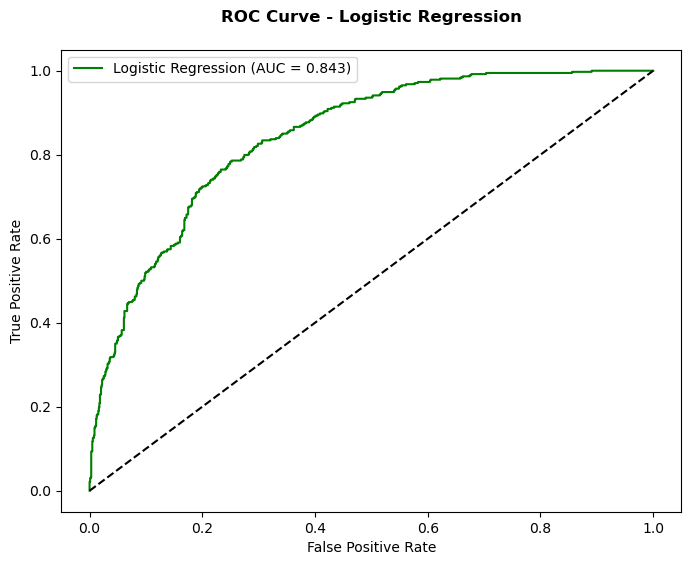

In [39]:
lr_model_y_proba = lr_model.predict_proba(X_test)[:, 1]


fpr, tpr, thresholds = roc_curve(y_test, lr_model_y_proba)
auc = roc_auc_score(y_test, lr_model_y_proba)


plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})", color="green")
plt.plot([0, 1], [0, 1], linestyle="--", color="black")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression", pad=20, fontweight="black")
plt.legend()
plt.show()

# KNN

In [ ]:
param_grid = {"n_neighbors": range(1, 81, 2)}
grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=10, scoring="roc_auc")
grid_search.fit(X_train, y_train)     # Tune K on original X_train first so SMOTE doesn't leak into the validation folds

best_k = grid_search.best_params_["n_neighbors"]
best_score = grid_search.best_score_
print(f"Best K: {best_k}")
print(f"Best Cross-Validation ROC AUC: {best_score:.3f}")

Best K: 59
Best Cross-Validation ROC AUC: 0.836


In [43]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_sm, y_train_sm)

KNeighborsClassifier(n_neighbors=59)

In [44]:
knn_model_y_pred = knn_model.predict(X_test)

In [46]:
knn_model_y_proba = knn_model.predict_proba(X_test)[:, 1]

knn_results = pd.DataFrame([{
    "Model": "KNN",
    "CV ROC-AUC (train)": best_score,
    "Accuracy": accuracy_score(y_test, knn_model_y_pred),
    "Precision": precision_score(y_test, knn_model_y_pred),
    "Recall": recall_score(y_test, knn_model_y_pred),
    "F1": f1_score(y_test, knn_model_y_pred),
    "ROC-AUC (test)": roc_auc_score(y_test, knn_model_y_proba),
}]).set_index("Model").round(3)

display(knn_results)

,CV ROC-AUC (train),Accuracy,Precision,Recall,F1,ROC-AUC (test)
Model,,,,,,
KNN,0.836,0.706,0.47,0.85,0.606,0.828


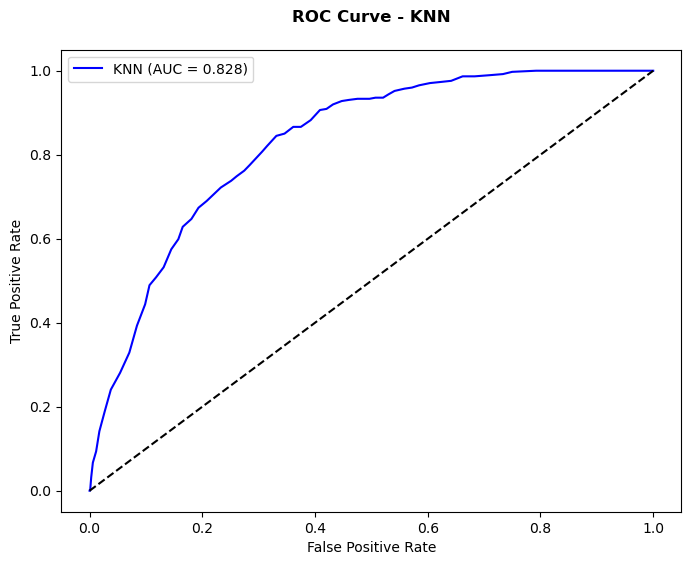

In [ ]:
knn_model_y_proba = knn_model.predict_proba(X_test)[:, 1]


fpr_knn, tpr_knn, thresholds_knn = roc_curve(y_test, knn_model_y_proba)
auc_knn = roc_auc_score(y_test, knn_model_y_proba)


plt.figure(figsize=(8, 6))
plt.plot(fpr_knn, tpr_knn, label=f"KNN (AUC = {auc_knn:.3f})", color="blue")
plt.plot([0, 1], [0, 1], linestyle="--", color="black")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN", pad=20, fontweight="black")
plt.legend()
plt.show()

# Decision Tree

In [48]:
param_grid = {"max_depth": range(1, 21)}
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=10, scoring="roc_auc")
grid_search.fit(X_train, y_train)  # Tune max_depth on original X_train first so SMOTE doesn't leak into the validation folds

best_depth = grid_search.best_params_["max_depth"]
best_score = grid_search.best_score_
print(f"Best Max Depth: {best_depth}")
print(f"Best Cross-Validation ROC AUC: {best_score:.3f}")

dt_model = DecisionTreeClassifier(max_depth=best_depth, random_state=42)

Best Max Depth: 5
Best Cross-Validation ROC AUC: 0.832


In [49]:
dt_model.fit(X_train_sm, y_train_sm)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [50]:
dt_model_y_pred = dt_model.predict(X_test)
dt_model_y_proba = dt_model.predict_proba(X_test)[:, 1]

dt_results = pd.DataFrame([{
    "Model": "Decision Tree",
    "CV ROC-AUC (train)": best_score,
    "Accuracy": accuracy_score(y_test, dt_model_y_pred),
    "Precision": precision_score(y_test, dt_model_y_pred),
    "Recall": recall_score(y_test, dt_model_y_pred),
    "F1": f1_score(y_test, dt_model_y_pred),
    "ROC-AUC (test)": roc_auc_score(y_test, dt_model_y_proba),
}]).set_index("Model").round(3)

display(dt_results)

,CV ROC-AUC (train),Accuracy,Precision,Recall,F1,ROC-AUC (test)
Model,,,,,,
Decision Tree,0.832,0.761,0.536,0.733,0.619,0.823


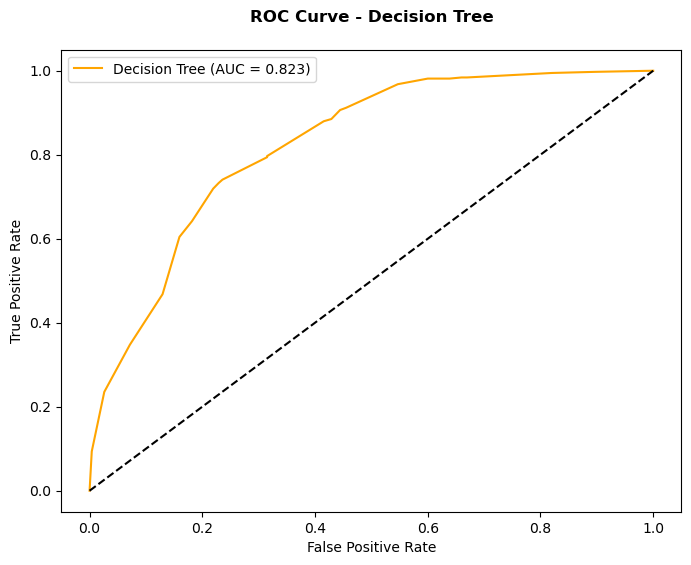

In [54]:
dt_model_y_proba = dt_model.predict_proba(X_test)[:, 1]

fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, dt_model_y_proba)
auc_dt = roc_auc_score(y_test, dt_model_y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc_dt:.3f})", color="orange")
plt.plot([0, 1], [0, 1], linestyle="--", color="black")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree", pad=20, fontweight="black")
plt.legend()
plt.show()

# SVM

In [51]:
param_grid = {"C": [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(SVC(probability=True, random_state=42), param_grid, cv=5, scoring="roc_auc")
grid_search.fit(X_train, y_train)  # Tune C on original X_train first so SMOTE doesn't leak into the validation folds

best_c = grid_search.best_params_["C"]
best_score = grid_search.best_score_
print(f"Best C: {best_c}")
print(f"Best Cross-Validation ROC AUC: {best_score:.3f}")

svm_model = SVC(C=best_c, probability=True, random_state=42)

Best C: 0.01
Best Cross-Validation ROC AUC: 0.820


In [52]:
svm_model.fit(X_train_sm, y_train_sm)

SVC(C=0.01, probability=True, random_state=42)

In [53]:
svm_model_y_pred = svm_model.predict(X_test)
svm_model_y_proba = svm_model.predict_proba(X_test)[:, 1]

svm_results = pd.DataFrame([{
    "Model": "SVM",
    "CV ROC-AUC (train)": best_score,
    "Accuracy": accuracy_score(y_test, svm_model_y_pred),
    "Precision": precision_score(y_test, svm_model_y_pred),
    "Recall": recall_score(y_test, svm_model_y_pred),
    "F1": f1_score(y_test, svm_model_y_pred),
    "ROC-AUC (test)": roc_auc_score(y_test, svm_model_y_proba),
}]).set_index("Model").round(3)

display(svm_results)

,CV ROC-AUC (train),Accuracy,Precision,Recall,F1,ROC-AUC (test)
Model,,,,,,
SVM,0.82,0.752,0.522,0.773,0.623,0.831


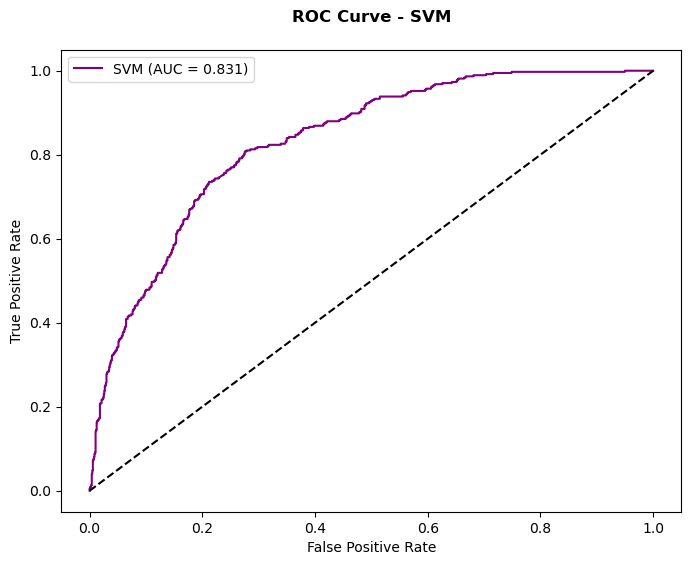

In [55]:
svm_model_y_proba = svm_model.predict_proba(X_test)[:, 1]

fpr_svm, tpr_svm, thresholds_svm = roc_curve(y_test, svm_model_y_proba)
auc_svm = roc_auc_score(y_test, svm_model_y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr_svm, tpr_svm, label=f"SVM (AUC = {auc_svm:.3f})", color="purple")
plt.plot([0, 1], [0, 1], linestyle="--", color="black")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM", pad=20, fontweight="black")
plt.legend()
plt.show()

# Compare performance

In [56]:
from sklearn.metrics import confusion_matrix

models = {
    "Logistic Regression": lr_model,
    "KNN": knn_model,
    "Decision Tree": dt_model,
    "SVM": svm_model
}

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "CV ROC-AUC (train)": cross_val_score(m, X_train_sm, y_train_sm, cv=5, scoring="roc_auc").mean(),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC (test)": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("F1", ascending=False)
display(results)

,CV ROC-AUC (train),Accuracy,Precision,Recall,F1,ROC-AUC (test)
Model,,,,,,
SVM,0.845,0.752,0.522,0.773,0.623,0.831
Logistic Regression,0.854,0.744,0.512,0.789,0.621,0.843
Decision Tree,0.863,0.761,0.536,0.733,0.619,0.823
KNN,0.851,0.706,0.470,0.850,0.606,0.828


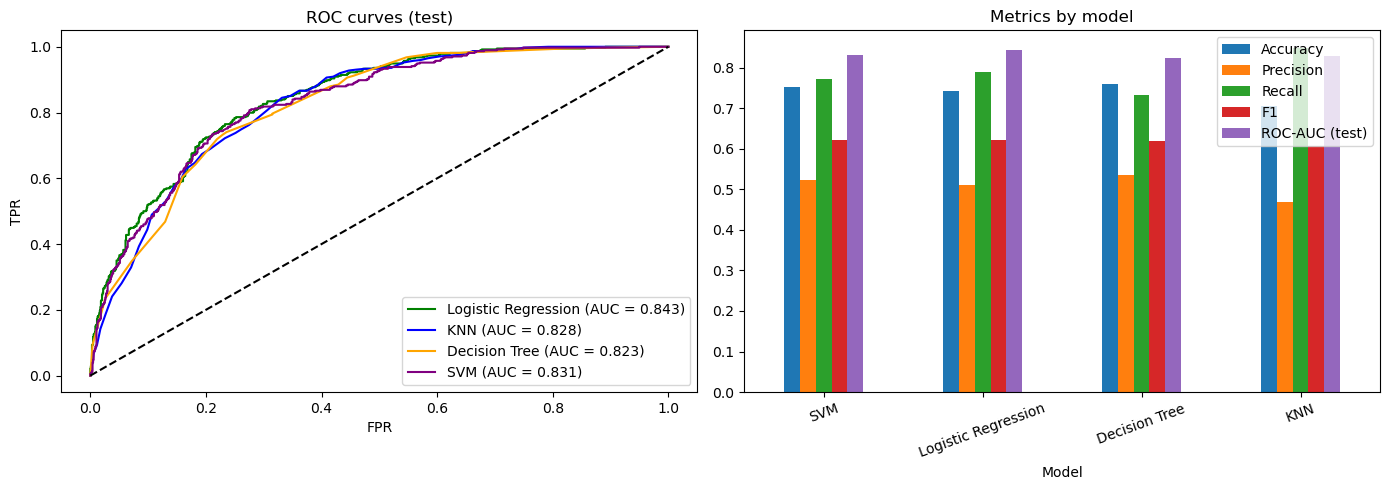

In [59]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

colors = {
    "Logistic Regression": "green",
    "KNN": "blue",
    "Decision Tree": "orange",
    "SVM": "purple"
}


for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=colors[name])

ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set_title("ROC curves (test)")
ax[0].set_xlabel("FPR")
ax[0].set_ylabel("TPR")
ax[0].legend()


results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC (test)"]].plot(kind="bar", ax=ax[1])
ax[1].set_title("Metrics by model")
ax[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()